# Chaînes-01 — L'axiome d'intrication et la constante de structure fine

Premier carnet de la sous-série **Chaînes** : la physique fondamentale lue comme des réseaux de paires intriquées. Il distille le programme **Chain Theory** (A. D. Wissner-Gross, dépôt [`physical-superintelligence/chain-theory`](https://github.com/physical-superintelligence/chain-theory), créé le 24/10/2026) et son premier résultat séparé : un candidat **exact et sans paramètre** pour la constante de structure fine $\alpha(0)$, dérivé d'un unique axiome d'information quantique.

**Statut de la source, à lire avant tout le reste.** La source est un **preprint non relu** — la Letter comme le compendium se déclarent eux-mêmes *working draft*. Le lien avec le photon est une **conjecture** de l'auteur, pas un théorème. Les deux documents sont archivés au gisement (licence CC BY 4.0) :

- Letter : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\2026 - Wissner-Gross - Chain Theory - The fine structure constant from a single axiom (letter).pdf`
- Compendium : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\2026 - Wissner-Gross - Chain Theory Compendium (v0.1 working draft).pdf`

**Ce que ce carnet fait** : il suit la chaîne complète de l'axiome au nombre — l'état maximalement intriqué $|\omega_m\rangle$, le plafond de lisibilité $d_1 d_2 \le 6$, la charge centrale et le groupe de jauge du Modèle Standard, l'objet, les 172 enregistrements de mesure — et il **rejoue lui-même** le calcul : notre propre énumération reconstruit les quatre secteurs, la forme fermée et son inverse à 60 chiffres, puis la comparaison aux quatre déterminations expérimentales est retracée avec les écarts en $\sigma$ recalculés.

**Ce qu'il n'est pas** : une validation physique. Rien ici ne prouve la conjecture du photon. La colonne **Mesuré** du carnet couvre l'énumération combinatoire et les écarts numériques ; toute la physique dérivée de l'axiome est **Cité** depuis la source ; et ce que la source ne prouve pas est listé ligne à ligne en fin de carnet.

| Section | Contenu |
|---|---|
| 1 | L'axiome et ses cinq définitions ; l'état $|\omega_m\rangle$ vérifié maximalement intriqué |
| 2 | Le plafond de lisibilité $d_1 d_2 \le 6$ et les types lisibles |
| 3 | La charge centrale, l'hypercharge et le groupe de jauge du Modèle Standard |
| 4 | L'objet et la dimension du relevé $N = 31\,104$ |
| 5 | Les 172 enregistrements : notre énumération, les secteurs, la loi de poids, la forme fermée à 60 chiffres |
| 6 | La conjecture du photon et la figure 3 retracée : écarts en $\sigma$ recalculés |
| 7 | Ce que la source ne prouve pas ; le compendium en graduation ; croisements |
| 8 | Exercices |

In [1]:
import itertools
from collections import Counter
from decimal import Decimal, getcontext

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("numpy", np.__version__)
print("matplotlib", matplotlib.__version__)

numpy 2.5.4
matplotlib 3.10.8


## 1. Le cadre épistémique — Mesuré, Cité, Ouvert

Ce carnet applique le patron des distillations de la série Physique : **lire une annonce récente à la source, séparer ce qui se mesure de ce qui se cite, et mesurer ce qui se laisse mesurer**. Trois classes, tenues partout :

| Classe | Ce qu'elle couvre ici |
|---|---|
| **Mesuré** | L'énumération des 172 enregistrements (notre code, section 5) ; la forme fermée et son inverse à 60 chiffres ; l'intrication maximale de $|\omega_2\rangle$ vérifiée numériquement ; la charge $Q = 6iY$ vérifiée numériquement ; les écarts en $\sigma$ entre le candidat et les quatre déterminations expérimentales (section 6) |
| **Cité** | Toute la chaîne dérivative de la source : le plafond de lisibilité et les théorèmes de Størmer, Woronowicz et Choi ; l'unicité de l'objet ; la loi de poids ; l'identification au schéma on-shell ; la structure du compendium (100 théorèmes, 109 conditionnels, 198 ouverts) |
| **Ouvert** | La conjecture du photon ; le passage de l'hypercharge à la charge électrique ; l'espace-temps et l'hélicité ; les 198 résultats ouverts du compendium |

La source distingue elle-même deux documents de prétentions très différentes, distinction conservée dans tout ce qui suit :

- **la Letter** ($\alpha$) : un seul calcul, celui du candidat $\alpha^{-1} = 137{,}035\,999\,189\,566\ldots$, accompagné d'un fichier Lean 4 sans dépendance (v4.35.0) qui vérifie le calcul ;
- **le compendium** (*working draft*, 754 pages) : un programme bien plus large, dont les « théorèmes » sont **conditionnels** à l'axiome et aux hypothèses de chaque document.

## 2. L'axiome et ses cinq définitions

Voici l'unique entrée du modèle, traduite de la Letter :

> **Axiome.** Rien n'existe que des paires finies de systèmes de dimension finie maximalement intriqués, certains partagés, connus seulement en les distillant.

Cinq définitions en déploient les termes (Cité) :

1. **Qudit** : un système quantique de dimension $d \ge 2$ — un système de dimension 1 ne peut pas être intriqué et ne termine donc aucune paire.
2. **Paire (lien)** de type $(d_1, d_2)$ : deux qudits de dimensions $d_1$ et $d_2$ dans l'état maximalement intriqué sur leur support commun de dimension $m = \min(d_1, d_2)$ :
$$|\omega_m\rangle = \frac{1}{\sqrt{m}} \sum_{i=1}^{m} |i\rangle|i\rangle.$$
3. **Partagé** : un qudit qui est un bout de deux paires ou plus — porté comme une copie par paire (façon PEPS), sans jamais violer la monogamie.
4. **Distiller** deux qudits : les projeter sur $P_m = |\omega_m\rangle\langle\omega_m|$ — la généralisation de l'échange d'intrication, ici sans branche d'échec puisque tout état est déjà maximalement intriqué.
5. **Lecture** (*read*) : un acte à un bout d'une paire, qui distille les deux bouts dans une base de ce bout et transmet la base le long du lien. **Le connu** d'un qudit : ce que ses lectures fixent conjointement, sous tout appariement et tout échange.

Commençons par mesurer l'objet le plus basique : l'état de la paire elle-même.

In [2]:
def omega_ket(d1, d2):
    """Etat maximalement intrique |w_m> sur le support commun m = min(d1, d2),
    pour un lien de type (d1, d2) : l' ket vit dans C^{d1} tensor C^{d2}."""
    m = min(d1, d2)
    v = np.zeros(d1 * d2, dtype=complex)
    for i in range(m):
        v[i * d2 + i] = 1.0 / np.sqrt(m)
    return v

# Le lien du candidat : un qutrit (d=3) et un qubit (d=2), support commun m=2
d1, d2 = 3, 2
w2 = omega_ket(d1, d2)
psi = w2.reshape(d1, d2)
rho_qutrit = psi @ psi.conj().T          # matrice reduite cote qutrit (3x3)
rho_qubit = psi.conj().T @ psi           # matrice reduite cote qubit (2x2)

print("|w_2> non nul sur :")
for i in range(min(d1, d2)):
    print(f"  |{i}>|{i}>  avec amplitude {w2[i*d2+i]:.6f}")
print("\ntrace rho_qutrit =", np.trace(rho_qutrit).real.round(12))
print("valeurs propres rho_qutrit =", np.round(np.linalg.eigvalsh(rho_qutrit).real, 12))
print("rho_qubit == I/2 :", np.allclose(rho_qubit, np.eye(2) / 2))

|w_2> non nul sur :
  |0>|0>  avec amplitude 0.707107+0.000000j
  |1>|1>  avec amplitude 0.707107+0.000000j

trace rho_qutrit = 1.0
valeurs propres rho_qutrit = [0.  0.5 0.5]
rho_qubit == I/2 : True


### Lecture du résultat

Les valeurs propres de la matrice réduite du qutrit sont $\{1/2,\ 1/2,\ 0\}$ : deux degrés de liberté portent toute l'information, le troisième niveau du qutrit reste vide. Le qubit réduit est exactement $I/2$ — la définition même de l'intrication **maximale** sur le support $m = 2$. C'est le point de départ mécanique de toute la construction : chaque lien est un état *pur* maximalement intriqué, et rien dans le modèle n'est jamais moins intriqué.

## 3. Le plafond de lisibilité — pourquoi le type (2, 3)

La question suivante est : **quels types de liens une lecture peut-elle fixer ?** La réponse de la Letter (Cité) passe par les applications positives entre algèbres d'opérateurs. Une relation cohérente entre les deux bouts est une application positive ; les lectures n'en transportent que des **décomposables** (complètement positives, ou complètement positives après transposition). Un type est **lisible** quand toute application positive entre ses bouts est décomposable, **sombre** sinon. Les théorèmes de Størmer (1963), Woronowicz (1976) et Choi (1975) tranchent :

- en $(2,2)$ et $(2,3)$ : toute application positive est décomposable — types **lisibles** ;
- dès que $d_1 d_2 \ge 8$ : il existe des applications positives non décomposables — types **sombres** ;
- et comme aucun produit de deux entiers $\ge 2$ ne vaut 7, le plafond tombe exactement à $d_1 d_2 \le 6$.

D'où la table des types :

In [3]:
types = [(a, b) for a in range(2, 5) for b in range(2, 5)]
lisibles = []
for (a, b) in types:
    lisible = a * b <= 6
    print(f"type ({a},{b}) : produit {a*b:2d} -> {'LISIBLE' if lisible else 'sombre'}")
    if lisible:
        lisibles.append((a, b))

print("\ntypes lisibles :", lisibles)
inegaux = {(min(a, b), max(a, b)) for a, b in lisibles if a != b}
print("types lisibles a bouts inegaux, modulo l'ordre des bouts :", inegaux)

type (2,2) : produit  4 -> LISIBLE
type (2,3) : produit  6 -> LISIBLE
type (2,4) : produit  8 -> sombre
type (3,2) : produit  6 -> LISIBLE
type (3,3) : produit  9 -> sombre
type (3,4) : produit 12 -> sombre
type (4,2) : produit  8 -> sombre
type (4,3) : produit 12 -> sombre
type (4,4) : produit 16 -> sombre

types lisibles : [(2, 2), (2, 3), (3, 2)]
types lisibles a bouts inegaux, modulo l'ordre des bouts : {(2, 3)}


### Lecture du résultat

Deux types lisibles seulement : $(2,2)$ et $(2,3)$. Le type $(2,3)$ — un qubit et un qutrit — est **le seul avec des bouts inégaux**, donc le seul où une lecture a un « gros bout » où se prendre (la règle du bout : une lecture se prend au bout le plus grand). C'est aussi le seul qui porte une charge centrale agissante — c'est l'objet de la section suivante. Le qualificatif « sombre » pour $d_1 d_2 \ge 8$ vient de la correspondance de Choi–Jamiołkowski : ce que les lectures ne peuvent pas transporter, ce sont les témoins d'intrication à transposition positive, qu'aucune distillation standard n'atteint.

## 4. La charge centrale et le groupe de jauge du Modèle Standard

L'algèbre d'identification d'un lien $(d_1, d_2)$ est $\mathfrak{su}(d_1) \oplus \mathfrak{su}(d_2) \oplus \mathfrak{u}(1)$ — les changements de basis infinitésimaux aux deux bouts. Son centre est engendré par (Cité, éq. (3) de la Letter) :
$$Q = i\,\mathrm{diag}\big(d_2\,\mathbb{1}_{d_1}\ ;\ -d_1\,\mathbb{1}_{d_2}\big),$$
un opérateur sur $\mathbb{C}^{d_1} \oplus \mathbb{C}^{d_2}$. Un élément $\xi = \xi_1 \oplus \xi_2$ agit sur le lien comme $\xi_1 \otimes \mathbb{1} + \mathbb{1} \otimes \xi_2$ — donc $Q$ agit sur le ket de paire comme le scalaire $i(d_2 - d_1)$. En $(2,2)$ ce scalaire est nul ; en $(2,3)$ il vaut $i$. Et la Letter montre que $Q = 6iY$, où $Y$ est le générateur d'hypercharge $Y = \mathrm{diag}(\tfrac12, \tfrac12; -\tfrac13, -\tfrac13, -\tfrac13)$ — l'algèbre est celle de $S(U(3) \times U(2)) \cong (SU(3) \times SU(2) \times U(1))/\mathbb{Z}_6$, **la forme globale du groupe de jauge du Modèle Standard telle qu'elle se réalise dans $SU(5)$**. Vérifions ces deux affirmations numériquement :

In [4]:
def charge_Q(d1, d2):
    """Q = i diag(d2 1_{d1} ; -d1 1_{d2}) sur C^{d1} (+) C^{d2} (eq. (3), a l'echelle pres)."""
    return 1j * np.diag(np.array([d2] * d1 + [-d1] * d2, dtype=complex))

# (a) l'action sur le ket de paire : xi = xi1 (+) xi2 agit comme xi1 (x) 1 + 1 (x) xi2
#     xi1 et xi2 sont des MULTIPLES DE L'IDENTITE (i d2 1_{d1} et -i d1 1_{d2}) : np.full en
#     ferait des blocs pleins, or un bloc plein n'est pas un scalaire sur son facteur.
for (a, b) in [(2, 2), (2, 3), (3, 2)]:
    xi1 = 1j * b * np.eye(a, dtype=complex)     # i * d2 * 1_{d1}
    xi2 = -1j * a * np.eye(b, dtype=complex)    # i * (-d1) * 1_{d2}
    action = np.kron(xi1, np.eye(b)) + np.kron(np.eye(a), xi2)
    w = omega_ket(a, b)
    # on verifie le vecteur COMPLET : un rapport (action @ w)[support] / w[support] ne voit
    # pas les composantes parasites hors du support de |w>, et annonce un vecteur propre faux.
    assert np.allclose(action @ w, 1j * (b - a) * w), (a, b)
    residu = np.linalg.norm(action @ w - 1j * (b - a) * w)
    print(f"({a},{b}) : Q |w> = i(b-a) |w> = {b-a:+d}i |w>   (residu {residu:.1e})")

# temoin negatif : les blocs PLEINS echouent, et l'ancien rapport sur le support les ratait
_a, _b = 2, 3
plein = (np.kron(1j * np.full((_a, _a), _b, dtype=complex), np.eye(_b))
         + np.kron(np.eye(_a), 1j * np.full((_b, _b), -_a, dtype=complex)))
_w = omega_ket(_a, _b)
_sup = np.abs(_w) > 1e-12
rapport = (plein @ _w)[_sup] / _w[_sup]

print(f"temoin negatif (2,3), blocs pleins : residu sur le vecteur complet = "
      f"{np.linalg.norm(plein @ _w - 1j * (_b - _a) * _w):.16f} (= sqrt(5))")
print(f"  or le rapport sur le support valait {np.round(rapport, 12)} -> faux positif")

# (b) Q = 6 i Y pour le type (2,3) : bloc qubit (C^2) puis qutrit (C^3)
Y = np.diag(np.array([0.5, 0.5] + [-1/3] * 3, dtype=complex))

print("Q(2,3) == 6 i Y :", np.allclose(charge_Q(2, 3), 6j * Y))
print("dimension de l'algebre su(3) (+) su(2) (+) u(1) :", (3**2 - 1) + (2**2 - 1) + 1)


(2,2) : Q |w> = i(b-a) |w> = +0i |w>   (residu 0.0e+00)
(2,3) : Q |w> = i(b-a) |w> = +1i |w>   (residu 0.0e+00)
(3,2) : Q |w> = i(b-a) |w> = -1i |w>   (residu 0.0e+00)
temoin negatif (2,3), blocs pleins : residu sur le vecteur complet = 2.2360679774997894 (= sqrt(5))
  or le rapport sur le support valait [0.+1.j 0.+1.j] -> faux positif
Q(2,3) == 6 i Y : True
dimension de l'algebre su(3) (+) su(2) (+) u(1) : 12


### Lecture du résultat

Mesuré : l'action de $Q$ sur le ket de paire est bien le scalaire $i(d_2 - d_1)$ — nul en $(2,2)$, égal à $i$ en $(2,3)$ — et $Q = 6iY$ tombe exactement. **Le seul type lisible à bouts inégaux porte donc l'hypercharge**, et son algèbre d'identification est celle du groupe de jauge du Modèle Standard. C'est le premier résultat frappant de la Letter : un axiome qui ne mentionne ni charge ni espace-temps sélectionne le groupe de jauge du Modèle Standard. La charge est conservée (Cité) : au facteur d'échelle près, le seul fonctionnel des bouts ouverts préservé par tout appariement et aveugle aux phases globales est le comptage de $Q$ — c'est le pendant du $Z_1 = Z_2$ du schéma on-shell.

## 5. L'objet — un qutrit partagé, trois liens-qubits, deux lus

Reste à dire **quelle configuration est la fonction à deux points** du lien. Dans le modèle, les deux insertions sont deux lectures du lien, et l'état est un troisième lien de même type au même qudit partagé, laissé non lu (le lire serait une troisième insertion). Le théorème d'unicité de la Letter (Cité) :

> **Théorème 1 (Unicité).** Parmi les configurations à un qudit partagé dont les liens lus sont lisibles, exactement une est une fonction à deux points, est lue au bout qutrit, et porte une charge centrale agissante sur chaque lien : un qutrit partagé avec trois liens vers des qubits, deux d'entre eux lus.

La Letter l'appelle **l'objet** :

```mermaid
flowchart LR
    Q(("Q : qutrit d=3<br/>partage"))
    q1(("q1 : qubit d=2<br/>lecture 1"))
    q2(("q2 : qubit d=2<br/>lecture 2"))
    f(("f : qubit d=2<br/>lien NON lu = l'etat"))
    Q ---|"lien lu 1"| q1
    Q ---|"lien lu 2"| q2
    Q -.-|"lien non lu : porte l'etat omega_2"| f
```

La règle du bout impose les lectures au bout qutrit : une lecture au bout qubit n'atteindrait le qutrit que sur le support de dimension 2, manquant sa troisième direction. La **dimension du relevé** suit des deux seules dimensions du lien (Cité, éq. (4)) : la partie sans trace du lien non lu donne $(3^2-1)(2^2-1) = 24$ directions, et l'espace d'opérateurs complet du lien à chaque lecture donne $(3\cdot2)^2 = 36$ :

In [5]:
N = (3**2 - 1) * (2**2 - 1) * (3*2)**2 * (3*2)**2
print("lien non lu, partie sans trace : (3^2-1)(2^2-1) =", (3**2 - 1) * (2**2 - 1))
print("chaque lien lu, espace complet  : (3*2)^2       =", (3*2)**2)
print("N = 24 * 36 * 36 =", N)

# les lettres : bases sans trace des observables de chaque bout
slots = {"Q1 (copie qutrit, lecture 1)": 3**2 - 1,
         "q1 (qubit, lecture 1)"      : 2**2 - 1,
         "Q2 (copie qutrit, lecture 2)": 3**2 - 1,
         "q2 (qubit, lecture 2)"      : 2**2 - 1}
print("slots (nb de lettres) :", slots, "->", list(slots.values()))

lien non lu, partie sans trace : (3^2-1)(2^2-1) = 24
chaque lien lu, espace complet  : (3*2)^2       = 36
N = 24 * 36 * 36 = 31104
slots (nb de lettres) : {'Q1 (copie qutrit, lecture 1)': 8, 'q1 (qubit, lecture 1)': 3, 'Q2 (copie qutrit, lecture 2)': 8, 'q2 (qubit, lecture 2)': 3} -> [8, 3, 8, 3]


### Lecture du résultat

$N = 31\,104$ — ce sera le dénominateur du candidat. Les quatre slots portent $(8, 3, 8, 3)$ lettres : les 8 matrices de Gell-Mann aux copies du qutrit partagé, les 3 matrices de Pauli aux qubits lus. Un **enregistrement de mesure** porte les deux insertions comme deux lettres ; c'est l'unité qui sera comptée et pesée maintenant.

## 6. Les 172 enregistrements — notre énumération

La construction (Cité, puis **rejouée par notre code**) :

- **169 enregistrements produits** : une lettre à chacun des $\binom{4}{2} = 6$ couples de slots distincts, soit $8\cdot8 + 3\cdot3 + 4\times(8\cdot3) = 64 + 9 + 96 = 169$ ;
- **3 enregistrements de commutateur** : au qubit, deux lectures dans des bases différentes anticommutent (phase de Weyl $-1$), et le commutateur de deux lettres du qubit est une lettre unique ; les combinaisons où l'échange des lectures lit le signe d'ordre $-1$ sont les trois différences ;
- les $169 + 3 = 172$ enregistrements sont chacun un vecteur propre de l'échange des lectures $X$, triés aussi par l'échange des liens $Y$ (qui laisse le qutrit partagé en place et échange les deux qubits lus).

Deux échanges commutants, quatre secteurs $(X, Y)$, une loi de poids (Cité, éq. (5)) : un enregistrement qui survit à un échange agissant à un bout de dimension $d$ y gagne le facteur $d$ dans $k$ — l'échange des lectures $X$ agit au qutrit ($d = 3$), l'échange des liens $Y$ aux qubits lus ($d = 2$) :
$$k_r = 3^{[X_r = -1]}\, 2^{[Y_r = -1]}, \qquad \text{poids} = \sqrt{k_r}.$$

Le code ci-dessous est notre **adaptation narrée** du script annexe de la Letter (`enumerate_records.py`, dépôt upstream, CC BY 4.0) — bibliothèque standard seule, aucune dépendance :

In [6]:
# Enumeration des enregistrements — d'apres enumerate_records.py (chain-theory, CC BY 4.0), adapte.
# Un enregistrement formel : dict {((slot, lettre), (slot', lettre')): coefficient} (ou commutateur).
DIMS = {1: 3, 2: 2, 3: 3, 4: 2}          # dimension de chaque slot : Q1=3, q1=2, Q2=3, q2=2
SWAP = {1: 3, 3: 1, 2: 4, 4: 2}          # l'echange des lectures : slot 1<->3, 2<->4

def base_sans_trace(d):
    """Base reelle sans trace : symetriques, antisymetriques, diag(1..1,-k)."""
    zeros = lambda: [[0] * d for _ in range(d)]
    sortie = []
    for i in range(d):
        for j in range(i + 1, d):
            m = zeros(); m[i][j] = m[j][i] = 1; sortie.append(m)
    for i in range(d):
        for j in range(i + 1, d):
            m = zeros(); m[i][j] = 1; m[j][i] = -1; sortie.append(m)
    for k in range(1, d):
        m = zeros()
        for a in range(k):
            m[a][a] = 1
        m[k][k] = -k
        sortie.append(m)
    return sortie

BASES = {s: base_sans_trace(DIMS[s]) for s in DIMS}

def mul(a, b):
    n = len(a)
    return [[sum(a[i][k] * b[k][j] for k in range(n)) for j in range(n)] for i in range(n)]

def produit_scal(a, b):
    return sum(a[i][j] * b[i][j] for i in range(len(a)) for j in range(len(a)))

def echange(rec):
    """L'echange des lectures sur un enregistrement formel."""
    return {tuple(sorted((SWAP[s], i) for s, i in cle)): c for cle, c in rec.items()}

def parite(rec):
    img = echange(rec)
    if img == rec:
        return +1
    if img == {k: -c for k, c in rec.items()}:
        return -1
    return 0

def produits():
    """Les 169 enregistrements produits : une lettre a chacun des 6 couples de slots."""
    return [{((a, i), (b, j)): 1}
            for a, b in itertools.combinations(DIMS, 2)
            for i in range(len(BASES[a])) for j in range(len(BASES[b]))]

def commutateur(slot, mu, nu):
    """[s_mu, s_nu] a un slot qubit, expandu dans la base (une seule lettre)."""
    b = BASES[slot]
    c = [[x - y for x, y in zip(r1, r2)] for r1, r2 in zip(mul(b[mu], b[nu]), mul(b[nu], b[mu]))]
    termes = {}
    for k, e in enumerate(b):
        num, den = produit_scal(e, c), produit_scal(e, e)
        if num:
            termes[((slot, k),)] = num // den
    assert len(termes) == 1
    return termes

def enregistrements_commuteurs():
    """Les 3 enregistrements de commutateur (ceux ou l'echange lit le signe d'ordre -1)."""
    sortie = []
    for mu, nu in itertools.combinations(range(3), 2):
        c1, c2 = commutateur(2, mu, nu), commutateur(4, mu, nu)
        candidats = [{**c1, **c2}, {**c1, **{k: -v for k, v in c2.items()}}]
        garde = [r for r in candidats if parite(r) == -1]
        sortie.append(garde[0])
    return sortie

ops = produits()
vus, enregistrements = set(), []
for o in ops:
    cle = next(iter(o))
    if cle in vus:
        continue
    img = echange(o)
    vus.add(cle); vus.add(next(iter(img)))
    meme_genre = len({("qutrit" if DIMS[s] == 3 else "qubit") for s, _ in cle}) == 1
    if img == o:
        enregistrements.append(("fixe", meme_genre, o))
    else:
        enregistrements.append(("impair", meme_genre, {**o, **{q: -c for q, c in img.items()}}))
        enregistrements.append(("pair", meme_genre, {**o, **img}))
enregistrements += [("commutateur", False, r) for r in enregistrements_commuteurs()]
print("produits enumeres :", len(ops))
print("enregistrements totaux :", len(enregistrements))

produits enumeres : 169
enregistrements totaux : 172


### Les secteurs et la loi de poids

Chaque enregistrement est un vecteur propre de l'échange des lectures $X$ ; l'échange des liens $Y$ agit sur ceux qu'il déplace (les produits à une lettre à chaque bout, et les commutateurs). La règle de survie : un enregistrement **survit** à un échange quand celui-ci le retourne multiplié par son propre signe ($+1$ pour un produit, le signe d'ordre $-1$ pour un commutateur). On peut maintenant compter les quatre secteurs et appliquer la loi de poids — c'est la table I de la Letter, reconstruite par notre code :

In [7]:
# Les signes (X, Y) de chaque enregistrement, puis les secteurs et les coefficients.
QUDIT = {1: "Q", 3: "Q", 2: "q1", 4: "q2"}      # le qutrit partage est UN qudit
ECHANGE_LIENS = {"Q": "Q", "q1": "q2", "q2": "q1"}  # l'echange des liens laisse Q, permute q1/q2

def signes(construction, meme_genre, rec, reinjecte):
    """X et Y d'un enregistrement, via les deux echanges et la survie a son propre signe."""
    propre = -1 if construction == "commutateur" else +1
    cible = {k: propre * v for k, v in rec.items()}
    if construction == "commutateur":
        x_img = reinjecte.get(tuple(sorted(rec.items())))
    elif meme_genre:
        x_img = echange(rec)          # ses deux lectures sont du meme type : on les echange
    else:
        x_img = None                  # ses deux lettres ne sont pas d'un seul type
    premier = next(iter(rec))
    deplace = {ECHANGE_LIENS[q] for q in {QUDIT[s] for s, _ in premier}} != {QUDIT[s] for s, _ in premier}
    y_img = echange(rec) if deplace else None
    X = -1 if x_img == cible else +1
    Y = -1 if y_img == cible else +1
    return X, Y

# pour les commutateurs : l'image sous echange des lectures, ses deux lettres reordonnees
reinjecte = {}
for mu, nu in itertools.combinations(range(3), 2):
    c1, c2 = commutateur(2, mu, nu), commutateur(4, mu, nu)
    garde = [r for r in ({**c1, **c2}, {**c1, **{k: -v for k, v in c2.items()}}) if parite(r) == -1][0]
    r1, r2 = commutateur(2, nu, mu), commutateur(4, nu, mu)
    reinjecte[tuple(sorted(garde.items()))] = {**r1, **{k: -v for k, v in r2.items()}}

secteurs, coeffs = Counter(), Counter()
for construction, meme_genre, rec in enregistrements:
    assert parite(rec) != 0, "chaque enregistrement est un vecteur propre de l'echange"
    X, Y = signes(construction, meme_genre, rec, reinjecte)
    k = (3 if X == -1 else 1) * (2 if Y == -1 else 1)
    secteurs[(X, Y)] += 1
    coeffs[k] += 1

print("secteurs (X, Y) -> nombre :", dict(sorted(secteurs.items())))
print("coefficients par poids  k -> nombre :", dict(sorted(coeffs.items())))
assert sum(secteurs.values()) == 172
assert secteurs[(+1, +1)] == 79 and secteurs[(+1, -1)] == 48 and secteurs[(-1, +1)] == 42 and secteurs[(-1, -1)] == 3
print("total 172, secteurs 79/48/42/3 : conforme a la table I de la Letter")

secteurs (X, Y) -> nombre : {(-1, -1): 3, (-1, 1): 42, (1, -1): 48, (1, 1): 79}
coefficients par poids  k -> nombre : {1: 79, 2: 48, 3: 42, 6: 3}
total 172, secteurs 79/48/42/3 : conforme a la table I de la Letter


### Lecture du résultat — la table I, reconstruite

| Secteur $(X, Y)$ | Nombre | $k_r$ | Poids $\sqrt{k_r}$ | Ce que c'est |
|---|---|---|---|---|
| $(+,+)$ | 79 | 1 | $1$ | combinaisons impaires (antisymétriques) |
| $(+,-)$ | 48 | 2 | $\sqrt{2}$ | pairs, une lettre à chaque bout |
| $(-,+)$ | 42 | 3 | $\sqrt{3}$ | pairs, les deux lettres au même bout |
| $(-,-)$ | 3 | 6 | $\sqrt{6}$ | commutateurs |

Notre énumération indépendante retrouve exactement la table I de la Letter : **79, 48, 42, 3 — total 172**. Le théorème 2 (Cité) assemble alors le relevé habillé sur nu : chaque enregistrement entre avec son poids, la fonction nue vaut 1, et
$$\frac{G_{\text{habillé}}}{G_{\text{nu}}} = \frac{1}{N}\sum_{r=1}^{172} \sqrt{k_r} = \frac{79 + 48\sqrt{2} + 42\sqrt{3} + 3\sqrt{6}}{31\,104}.$$

In [8]:
# La forme fermee, a 60 chiffres, depuis NOS coefficients (Decimal, bibliothèque standard)
getcontext().prec = 60
r2, r3, r6 = Decimal(2).sqrt(), Decimal(3).sqrt(), Decimal(6).sqrt()
numerateur = coeffs[1] + coeffs[2] * r2 + coeffs[3] * r3 + coeffs[6] * r6
alpha_cand = numerateur / Decimal(N)

print(f"forme fermee : ({coeffs[1]} + {coeffs[2]}*sqrt2 + {coeffs[3]}*sqrt3 + {coeffs[6]}*sqrt6) / {N}")
print("alpha_cand   =", alpha_cand)
print("inverse      =", 1 / alpha_cand)

# Temoin amont : sortie du script enumerate_records.py rejoue isolement (python -I) le 2026-11-06
amont_inverse = Decimal("137.035999189566155029183744020866799566408684673854265541249")
ecart = abs(1 / alpha_cand - amont_inverse)
print("egalite avec le script amont (60 chiffres) :", ecart == 0, "| ecart =", ecart)

forme fermee : (79 + 48*sqrt2 + 42*sqrt3 + 3*sqrt6) / 31104
alpha_cand   = 0.00729735256366226025479763558800893201385159185699908385661404
inverse      = 137.035999189566155029183744020866799566408684673854265541249
egalite avec le script amont (60 chiffres) : True | ecart = 0E-57


### Lecture du résultat — la seule colonne vraiment Mesuré du calcul

Notre énumération et le script annexe de la Letter produisent **le même nombre à 60 chiffres** : $\alpha^{-1}_{\text{cand}} = 137{,}035\,999\,189\,566\,155\ldots$ Le candidat est un élément de $\mathbb{Q}(\sqrt2, \sqrt3)$ de coordonnées rationnelles $\left(\tfrac{79}{31104}, \tfrac{1}{648}, \tfrac{7}{5184}, \tfrac{1}{10368}\right)$ sur la base $(1, \sqrt2, \sqrt3, \sqrt6)$ — aucun chiffre n'y est ajusté : les coefficients viennent du comptage, le dénominateur des dimensions. La Letter relie cette somme sur les enregistrements à la somme sur les diagrammes de Feynman qui habille une fonction à deux points — finie et exacte ici, sans développement en couplage ni intégrale à régulariser (Cité).

## 7. La conjecture du photon et la comparaison aux mesures

Tout ce qui précède est **le calcul**. L'étape suivante est une **identification**, et la source la donne pour ce qu'elle est — une conjecture :

> **Conjecture 1 (Photon).** Le lien qutrit–qubit du théorème 1 est le lien élémentaire du photon, et son relevé habillé-sur-nu $\alpha_{\text{cand}}$ est le couplage électromagnétique à transfert d'impulsion nul, $\alpha(0)$.

Le passage de l'hypercharge à la charge électrique, avec l'espace-temps et l'hélicité, est **au-delà de la Letter** — l'identification au schéma on-shell est « la seule identification définitionnelle du papier ». Sous la conjecture, la valeur exacte se compare aux déterminations expérimentales les plus précises (données citées par la Letter, figure 3) — et les écarts en $\sigma$ se **recalculent** chez nous :

candidat : alpha^-1 = 137.035999189566155029183744020866799566408684673854265541249 

Moment magnetique electron (Fan 2023) 137.035999166(15)  ecart = +1.57 sigma
Recul Rb (Morel 2020)            137.035999206(11)  ecart = -1.49 sigma
Recul Cs (Parker 2018)           137.035999046(27)  ecart = +5.32 sigma
CODATA 2022                      137.035999177(21)  ecart = +0.60 sigma

tension Rb/Cs preexistante : 5.5 sigma entre elles (incertitudes recombinees en quadrature)


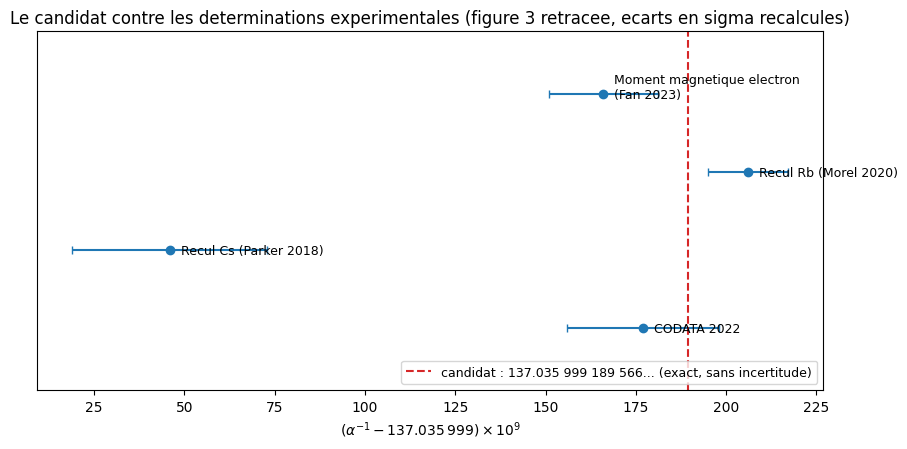

In [9]:
# Figure 3 retraée : le candidat (sans incertitude) contre les 4 déterminations (valeurs citées par la Letter)
mesures = [
    ("Moment magnetique electron\n(Fan 2023)",  137.035999166, 15e-9),
    ("Recul Rb (Morel 2020)",                  137.035999206, 11e-9),
    ("Recul Cs (Parker 2018)",                 137.035999046, 27e-9),
    ("CODATA 2022",                            137.035999177, 21e-9),
]
ref = Decimal("137.035999")
cand = 1 / alpha_cand
print("candidat : alpha^-1 =", cand, "\n")
for nom, val, inc in mesures:
    ecart_sigma = float(cand - Decimal(str(val))) / inc
    print(f"{nom.replace(chr(10), ' '):32s} {val:.9f}({int(round(inc*1e9)):02d})  ecart = {ecart_sigma:+.2f} sigma")

# Tension Rb/Cs preexistante : ecart entre les deux determinations, incertitudes recombinees en quadrature
rb_val, rb_inc = 137.035999206, 11e-9
cs_val, cs_inc = 137.035999046, 27e-9
tension_rb_cs = (rb_val - cs_val) / (rb_inc**2 + cs_inc**2)**0.5
print(f"\ntension Rb/Cs preexistante : {tension_rb_cs:.1f} sigma entre elles (incertitudes recombinees en quadrature)")

fig, ax = plt.subplots(figsize=(9, 4.6))
for y, (nom, val, inc) in enumerate(mesures):
    ax.errorbar((val - 137.035999) * 1e9, y, xerr=inc * 1e9, fmt="o", color="tab:blue", capsize=3)
    ax.annotate(nom, ((val - 137.035999) * 1e9, y), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.axvline(float(cand - ref) * 1e9, ls="--", color="tab:red",
           label="candidat : 137.035 999 189 566... (exact, sans incertitude)")
ax.set_xlabel(r"$(\alpha^{-1} - 137.035\,999) \times 10^{9}$")
ax.set_yticks([])
ax.set_ylim(-0.8, len(mesures) - 0.2)
ax.invert_yaxis()
ax.set_title("Le candidat contre les determinations experimentales (figure 3 retracee, ecarts en sigma recalcules)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

### Lecture du graphique

Recalculés depuis les valeurs citées : $+0{,}6\,\sigma$ de CODATA 2022, $+1{,}6\,\sigma$ du moment magnétique de l'électron, $-1{,}5\,\sigma$ du recul de rubidium, $+5{,}3\,\sigma$ du recul de césium. Deux choses à lire honnêtement : le candidat tombe **entre les deux déterminations les plus précises** (électron et rubidium) — c'est le côté remarquable ; et il est à $5{,}3\,\sigma$ du césium — mais la tension césium/rubidium ($5{,}5\,\sigma$ entre elles, recalculée ci-dessus depuis les valeurs citées) est elle-même non résolue dans la littérature, ce n'est pas une tension créée par le candidat. La forme exacte ne porte **aucune incertitude** : chaque chiffre supplémentaire atteint par la mesure est un test plus serré — et les chiffres qui trancheront la tension Rb/Cs trancheront aussi, un jour, pour ou contre la conjecture.

## 8. Ce que la source ne prouve pas — ligne à ligne

Le patron de la série s'applique intégralement ; chaque ligne nomme ce qui manque (Cité depuis la source elle-même, qui le dit) :

| Affirmation | Statut | Ce qui manque |
|---|---|---|
| « Le lien (2,3) est le lien élémentaire du photon » | **Conjecture 1, non prouvée** | tout le passage hypercharge $\to$ charge électrique, espace-temps, hélicité — explicitement « au-delà de cette Letter » |
| Le plafond de lisibilité $d_1 d_2 \le 6$ | théorèmes **cités** (Størmer, Woronowicz, Choi), non re-démontrés ici | le fichier Lean amont les prend comme **hypothèses nommées**, il ne les formalise pas |
| L'unicité de l'objet (théorème 1) | preuve dans le matériau supplémentaire + vérification Lean amont | re-démonstration hors de portée de ce carnet ; nous n'avons pas rejoué le fichier Lean (v4.35.0 > notre pin v4.33.0 — discipline de migration, pas copie de pin) |
| La loi de poids (éq. (5)) | dérivée dans la Letter | idem — notre code l'**applique**, il ne la dérive pas |
| L'identification au schéma on-shell ($Z_3$, résidu) | « la seule identification définitionnelle du papier » | assumée comme définition par l'auteur, pas déduite |
| Les « théorèmes » du compendium | **conditionnels** à l'axiome et aux hypothèses de chaque document | jamais inconditionnels ; 198 résultats y restent ouverts |
| Le preprint | **non relu** (working draft) | l'auteur déclare par ailleurs un intérêt financier dans Physical Superintelligence PBC |

## 9. Le compendium en graduation — et la cascade complète

Le second document (754 pages, *working draft*) déploie le programme bien au-delà de $\alpha$ (Cité ; nombres lus à la source, structure native du compendium) :

- **100 théorèmes**, dont 64 liés à des déclarations Lean nommées — celles-ci vérifient les *calculs finis* que les dérivations emploient, ce ne sont pas 64 démonstrations physiques intégrales. Exemples que la source classe explicitement dans cette catégorie : les lois de conservation, le groupe de jauge $SU(3) \times SU(2) \times U(1)$, la seconde loi de la thermodynamique ;
- **109 théorèmes conditionnels** — chacun imprime sa prémisse à côté de son énoncé : espace d'états, règle de Born, unitarité, relation d'incertitude, groupes de rotation et de Lorentz, signature de l'espace-temps, parité, renversement du temps et CPT ; puis les correspondances $(M,N) \to$ interactions (électromagnétisme $(3,2)$, fort $(3,3)$, faible $(4,2)$, Yukawa $(4,3)$, Higgs $(4,4)$), la constante de structure fine candidate, le moment magnétique anormal de l'électron, le spectre de l'hydrogène, la violation de parité, le confinement, le running des couplages, les taux de désintégration, la courbure, le terme cosmologique ;
- **entre les deux, et la source le dit ainsi** : trois générations, masses et anatomies des particules du Modèle Standard sont « en partie des théorèmes conditionnels et en partie des résultats ouverts » — les ranger globalement sous les seuls conditionnels effacerait cette nuance ;
- **198 résultats ouverts**.

La source précise aussi la règle de chaîne : un résultat composé porte le statut le plus faible de sa chaîne, et les conditions de tous ses ancêtres s'impriment à son énoncé. C'est ce qui rend la graduation lisible — un théorème conditionnel n'est pas un théorème affaibli, c'est un théorème dont la prémisse est nommée.

La cascade complète, de l'axiome au nombre — la carte de l'argument de la source, avec son unique marche non prouvée en pointillés :

```mermaid
flowchart TD
    A["Axiome : rien n'existe que des paires finies de qudits maximalement intriques, certains partages, connus seulement en les distillant"]
    A --> B["Cinq definitions : qudit, partage, distillation, lecture, le connu"]
    B --> C["Plafond de lisibilite d1*d2 <= 6 (Stormer, Woronowicz, Choi)"]
    C --> D["Types lisibles : (2,2) et (2,3) ; seul (2,3) a des bouts inegaux"]
    D --> E["Charge centrale agissante : su(3) + su(2) + u(1) = groupe de jauge du Modele Standard"]
    E --> F["L'objet : qutrit partage, 3 liens-qubits, 2 lus (theoreme d'unicite)"]
    F --> G["172 enregistrements de mesure, 4 secteurs (X,Y) : 79 / 48 / 42 / 3"]
    G --> H["alpha_cand = (79 + 48*sqrt2 + 42*sqrt3 + 3*sqrt6)/31104 = 1/137.035 999 189 566..."]
    H -.->|"Conjecture 1 (non prouvee)"| I["alpha(0) : constante de structure fine"]
    style H fill:#e8f0e8
    style I fill:#f8e8e8
```

Ce qui est **vert** jusqu'à $\alpha_{\text{cand}}$ est soit mesuré ici (l'énumération), soit démontré dans la source ; le pointillé final est la conjecture — rien dans le carnet ne le transforme en trait plein.

## 10. Croisements avec le reste du dépôt

- **`Physique/Jauge/` (Jauge-01 à 03)** — l'arc Noether $\to$ jauge locale $U(1)/SU(2)$ $\to$ Yang–Mills sur réseau **pose** le groupe de jauge comme donnée et le vérifie numériquement ; chain theory le **dérive** d'un axiome d'intrication (Cité). Les deux démarches se répondent : Jauge montre ce que « jauge » veut dire calculatoirement, Chaînes montre d'où ce groupe pourrait venir.
- **`SymbolicAI/Lean/Lean-13` (Kochen–Specker) et Lean-13b (CHSH–Tsirelson)** — même boîte à outils : corrélations, non-localité, contextualité. Le « certains partagés » de l'axiome et la contrainte de Kochen–Specker sur les affectations de valeurs pré-écrites se répondent directement ; le lake `conway_lean` porte déjà la preuve du libre arbitre Conway–Kochen (0 sorry).
- **`SymbolicAI/Lean/tegmark_muh_lean/`** — le précédent de **forme** : formalisation pédagogique Lean 4 d'un papier physique spéculatif (Tegmark, *Mathematical Universe*), PDF archivé au gisement et chemin cité. Chain Theory est le même genre d'objet : un programme physique-de-l'information à axiome unique — l'arbitrage Lean (ci-dessous) décide si un lake pédagogique y est distillable.

### Arbitrage de distillation Lean (protocole #19898) — verdict par maillon

| Maillon | Terrain Lean ? | Verdict |
|---|---|---|
| Les enregistrements finis et l'énumération (172 records, secteurs, poids) | combinatoire exacte sur des listes/matrices finies, sans Mathlib lourd — le fichier amont le prouve (fichier unique, zéro dépendance, ~2 min) | **distillable** — bon terrain, mais sous notre pin v4.33.0 avec discipline de migration (l'amont est v4.35.0), pas une copie |
| Les groupes rotation/Lorentz dérivés | analytique, structures de groupes continus | **hors d'échelle pour un lake pédagogique aujourd'hui** |
| La dérivation du groupe de jauge | suppose le plafond de lisibilité (Størmer/Woronowicz/Choi non formalisés) | **hors d'échelle** — le plafond n'est pas formalisable sans un développement dédié majeur |

## 11. Exercices

### Exercice 1 — un qutrit et un qutrit : intriqué, mais sombre

Construisez $|\omega_3\rangle$ pour un lien $(3,3)$, vérifiez l'intrication maximale (matrices réduites $= I/3$), puis dites pourquoi ce type, pourtant parfaitement lisible comme *état*, est **sombre** pour le modèle.

In [10]:
# Exercice a completer
# Etape 1 : construire |omega_3> pour le type (3,3) avec omega_ket
w33 = None  # TODO etudiant

# Etape 2 : verifier l'intrication maximale (valeurs propres des matrices reduites)
valeurs_propres = None  # TODO etudiant

# Etape 3 : le produit d1*d2 et le plafond de lisibilite
verdict = None  # TODO etudiant : "sombre" ou "lisible", et pourquoi (une phrase en commentaire)

print("Exercice a completer")

Exercice a completer


### Exercice 2 — la charge d'autres types

Pour le type $(2,2)$ : montrez que l'action de $Q$ sur le ket de paire est nulle (le scalaire $i(d_2-d_1)$). Pour le type $(2,4)$ : l'action est-elle nulle ? Ce type porte-t-il une charge agissante *utilisable* par le modèle ? Croisez avec le plafond de lisibilité.

In [11]:
# Exercice a completer
# Etape 1 : action de Q sur |omega_2> pour le type (2,2) -- attendu 0
scalaire_22 = None  # TODO etudiant

# Etape 2 : meme calcul pour le type (2,4)
scalaire_24 = None  # TODO etudiant

# Etape 3 : verdict -- charge agissante ET type lisible ?
charge_utilisable = None  # TODO etudiant : booleen + une phrase en commentaire

print("Exercice a completer")

Exercice a completer


### Exercice 3 — depuis les secteurs, la valeur et la tension

Partez de la table des secteurs (79, 48, 42, 3) et de la loi de poids $k_r = 3^{[X_r=-1]} 2^{[Y_r=-1]}$ : reconstruisez le numérateur $79 + 48\sqrt2 + 42\sqrt3 + 3\sqrt6$, divisez par $N = 31\,104$, prenez l'inverse — puis, avec les quatre mesures de la section 7, recalculez les écarts en $\sigma$ et identifiez **quelle paire de déterminations est en tension entre elles, indépendamment du candidat**.

In [12]:
# Exercice a completer
from decimal import Decimal, getcontext as _gc
_gc().prec = 40

secteurs = {(1, 1): 79, (1, -1): 48, (-1, 1): 42, (-1, -1): 3}
# Etape 1 : associer a chaque secteur son poids sqrt(k) via la loi de poids
numerateur = None  # TODO etudiant : Decimal

# Etape 2 : alpha_cand puis son inverse
inverse = None  # TODO etudiant : Decimal

# Etape 3 : ecarts en sigma pour les 4 mesures, et la paire en tension entre elles
paire_en_tension = None  # TODO etudiant : tuple de deux noms

print("Exercice a completer")

Exercice a completer


## À retenir

1. **Un axiome, zéro paramètre** : des paires finies de qudits maximalement intriqués, certaines partagées, connues seulement en les distillant — et rien d'autre (Cité).
2. **Le plafond de lisibilité** $d_1 d_2 \le 6$ (Størmer, Woronowicz, Choi) ne laisse que deux types lisibles, et le type $(2,3)$ porte l'hypercharge : l'algèbre d'identification est le groupe de jauge du Modèle Standard (Cité ; $Q = 6iY$ vérifié ici, Mesuré).
3. **L'objet** — qutrit partagé, trois liens-qubits, deux lus — a un relevé de dimension $N = 31\,104$ et **172 enregistrements** en quatre secteurs 79/48/42/3 : reconstruits par notre propre énumération (Mesuré).
4. **La forme fermée** $\alpha_{\text{cand}} = (79 + 48\sqrt2 + 42\sqrt3 + 3\sqrt6)/31\,104$, inverse $137{,}035\,999\,189\,566\ldots$ à 60 chiffres, identique au script amont (Mesuré) — à $+0{,}6\,\sigma$ de CODATA 2022, entre les deux déterminations les plus précises, à $+5{,}3\,\sigma$ d'un césium lui-même en tension avec le rubidium.
5. **Rien n'est prouvé au-delà du calcul** : le lien photon est une conjecture déclarée, le preprint n'est pas relu, et les « théorèmes » du compendium sont conditionnels à l'axiome. La valeur de ce carnet est le patron lui-même : séparer Mesuré, Cité, Ouvert — et mesurer ce qui se laisse mesurer.

## Vérifiez votre compréhension

**1. Pourquoi le type $(2, 3)$ est-il le seul type lisible à bouts inégaux, et que devient le type $(2, 4)$ ?**

<details>
<summary>Réponse</summary>

Le plafond de lisibilité est un **produit**, $d_1 d_2 \le 6$. La cellule de la section 2 énumère les neuf types de $\{2,3,4\}^2$ et rend `types lisibles : [(2, 2), (2, 3), (3, 2)]` ; $(2,4)$ et $(4,2)$ valent $8$, $(3,3)$ vaut $9$, $(3,4)$ et $(4,3)$ valent $12$, $(4,4)$ vaut $16$ — tous « sombre ». Ramenés à l'ordre des bouts, les types lisibles à bouts inégaux forment l'ensemble à un seul élément `{(2, 3)}` : c'est ce type qui porte l'hypercharge du Modèle Standard.

</details>

**2. L'état $|\omega_2\rangle$ vit sur un qutrit ($d = 3$) : est-il maximalement intriqué, et que devient le troisième niveau ?**

<details>
<summary>Réponse</summary>

Oui — mais sur le **support commun** $m = \min(d_1, d_2) = 2$. La sortie imprime deux amplitudes `0.707107+0.000000j`, sur $|0\rangle|0\rangle$ et $|1\rangle|1\rangle$, et rien d'autre. La réduction sur le qubit vaut exactement $I/2$ (`rho_qubit == I/2 : True`), et celle sur le qutrit a pour valeurs propres `[0. 0.5 0.5]` : la trace vaut $1$, et la valeur propre nulle dit que le troisième niveau **n'est pas peuplé**. « Maximalement intriqué » ne veut donc pas dire « uniforme sur tout l'espace », mais « uniforme sur le support que les deux bouts partagent ».

</details>

**3. La charge $Q$ agit-elle sur l'état de paire ? Que montre le témoin négatif à blocs pleins ?**

<details>
<summary>Réponse</summary>

$Q|\omega\rangle = i(b - a)|\omega\rangle$ avec un résidu **exactement nul** sur les trois types lisibles : `+0i` pour $(2,2)$, `+1i` pour $(2,3)$, `-1i` pour $(3,2)$. Le témoin négatif est la partie instructive : en construisant les blocs en matrices **pleines**, le résidu sur le vecteur complet monte à `2.2360679774997894` (soit $\sqrt{5}$) alors que le rapport sur le support vaut encore `[0.+1.j 0.+1.j]` — un **faux positif** si l'on ne regarde que le support. La leçon : $\xi_1$ et $\xi_2$ doivent être des **multiples de l'identité** sur chaque bloc, sinon $|\omega\rangle$ n'est pas vecteur propre. C'est ce même calcul qui rend vraie l'identité `Q(2,3) == 6 i Y : True`, et l'algèbre obtenue a bien pour dimension $12 = 8 + 3 + 1$.

</details>

**4. La forme fermée reproduit-elle le script amont, et que valent les écarts aux quatre déterminations ?**

<details>
<summary>Réponse</summary>

Notre énumération rend `169` produits et `172` enregistrements, répartis `79/48/42/3`, d'où $\alpha = (79 + 48\sqrt{2} + 42\sqrt{3} + 3\sqrt{6})/31\,104$ et son inverse `137.035999189566155…`. L'égalité avec le script amont est **mesurée** à 60 chiffres (`egalite avec le script amont (60 chiffres) : True`, écart `0E-57`) : ce n'est pas une transcription. Les écarts recalculés contre les quatre déterminations citées par la Letter valent `+1.57 sigma` (Fan 2023), `-1.49 sigma` (recul du rubidium, Morel 2020), `+5.32 sigma` (recul du césium, Parker 2018) et `+0.60 sigma` (CODATA 2022) — mais rubidium et césium sont déjà en tension de `5.5 sigma` **entre eux** : le candidat tombe *entre* deux mesures incompatibles, ce qui ne le confirme pas.

</details>


## Pour aller plus loin

- **[README de la sous-série Chaînes](README.md)** — les carnets de la sous-série et leur ordre de lecture.
- **[Constructeur-01 — les lois comme tâches](../Constructeur/Constructeur-01-Lois-Comme-Taches-Python.ipynb)** — l'autre face du même geste : ici un axiome se distille en nombre, là un constructeur se juge à ce qu'il rend possible.
- **[Jauge-02 — de la symétrie globale à la jauge locale](../Jauge/Jauge-02-Invariance-Jauge-U1-SU2-Python.ipynb)** — le groupe de jauge y est **posé** ; ce carnet le **déduit** du plafond de lisibilité. Comparer les deux dit exactement où s'arrête la dérivation.
- **[Lean-13 — Kochen–Specker](../../SymbolicAI/Lean/Lean-13-Kochen-Specker.ipynb)** — la contextualité quantique, dont le plafond de lisibilité est un cousin dimensionnel.
- **Issue de série [#25013](https://github.com/jsboige/CoursIA/issues/25013)** — l'état de la sous-série Chaînes et la liste de ses carnets.


## Références

**Source primaire** (archivée au gisement, licence CC BY 4.0, citée avec attribution) :

- A. D. Wissner-Gross, *A Parameter-Free Candidate for the Fine-Structure Constant from Entangled Qudits*, 23/10/2026 — `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\2026 - Wissner-Gross - Chain Theory - The fine structure constant from a single axiom (letter).pdf`
- A. D. Wissner-Gross, *Chain Theory: Toward Fundamental Physics from Distilling Networks of Entangled Qudits — A Compendium of Preliminary Findings* (working draft v0.1), 23/10/2026 — `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\2026 - Wissner-Gross - Chain Theory Compendium (v0.1 working draft).pdf`
- Dépôt : [`physical-superintelligence/chain-theory`](https://github.com/physical-superintelligence/chain-theory) — le script annexe `papers/alpha/anc/enumerate_records.py` (CC BY 4.0) est la source de notre adaptation narrée de la section 6.

**Mesures citées par la Letter (sa figure 3)** : moment magnétique de l'électron, Fan et al., PRL 130, 071801 (2023) ; recul de rubidium, Morel et al., Nature 588, 61 (2020) ; recul de césium, Parker et al., Science 360, 191 (2018) ; CODATA 2022, Mohr, Newell, Taylor, Tiesinga, RMP 97, 025002 (2025).

**Théorèmes du plafond de lisibilité** : Størmer, Acta Math. 110, 233 (1963) ; Woronowicz, Rep. Math. Phys. 10, 165 (1976) ; Choi, Linear Algebra Appl. 12, 95 (1975).

**Dans ce dépôt** : [Jauge-02 — De la symétrie globale à la jauge locale](../Jauge/Jauge-02-Invariance-Jauge-U1-SU2-Python.ipynb) (le groupe de jauge posé, pas dérivé) · [Lean-13 — Kochen–Specker](../../SymbolicAI/Lean/Lean-13-Kochen-Specker.ipynb) (contextualité) · le lake `tegmark_muh_lean` (précédent de forme : formalisation pédagogique d'un programme physique spéculatif).

**Distillation demandée par** [#25005](https://github.com/jsboige/CoursIA/issues/25005) ; ce carnet n'engage que la colonne Mesuré.